# Power Analysis for the IAAFT Surrogate Correlation Test

**Revision response #2-6** — *"Only 4 genes pass significance for $w_{WT}$; this small number limits
biological conclusions. Provide power analysis and discuss limitations."*

---

## Purpose

This notebook quantifies the **statistical power** (detection rate) of the surrogate-based
correlation test used to link the estimated signal importance $w_{WT}$ to gene-expression
profiles. It answers the reviewer's question directly:

> *Given the sample size and the multiple-testing correction actually used, how strong must a
> true correlation be before this test can reliably detect it?*

## Test structure (identical to the manuscript)

| Element | Definition |
|---|---|
| **Test statistic** | $r_{\mathrm{obs}} = \mathrm{corr}(w_{WT},\, g)$ — Pearson correlation between the signal importance and a comparison signal $g$ |
| **Null distribution** | $\{\mathrm{corr}(w_{WT}^{\mathrm{surr}_i},\, g)\}_{i=1}^{M}$ over $M=10^5$ **IAAFT surrogates** of $w_{WT}$ (phase-randomised; preserves the power spectrum, i.e. the autocorrelation structure) |
| **Decision** | Reject $H_0$ if $r_{\mathrm{obs}}$ falls in the upper $\alpha$ tail (one-sided) |
| **Significance levels** | per-gene $p = 0.05$, and **Bonferroni-corrected $p = 0.05/21 \approx 0.0024$** for the 21 tested genes |

## Power-analysis design

For a target *population* correlation $\rho$, we synthesise a comparison signal

$$ g \;=\; \rho\,\tilde{w}_{WT} \;+\; \sqrt{1-\rho^{2}}\;\varepsilon , \qquad \varepsilon \sim \mathcal{N}(0,1)\ \text{i.i.d.} $$

where $\tilde{w}_{WT}$ is the standardised $w_{WT}$. By construction the population Pearson
correlation between $w_{WT}$ and $g$ is exactly $\rho$. We then run the **identical** surrogate
test, repeat $T$ times, and record the **positive rate** — which is the power at that $\rho$.

**Sample size:** the correlation is evaluated on $n = 24$ time points (the 48-point series with
the even-numbered points removed).

---

## 1. Setup

Requires `iaaft.py` (https://github.com/mlcs/iaaft) on the Python path.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

import iaaft

SEED = 20260806
np.random.seed(SEED)

# ---- configuration -----------------------------------------------------
RESULT_DIR = "../results/"                     # adjust if needed
CSV_NAME   = "SignalImportance_average.csv"
FACTOR     = "WT"                              # signal to analyse

M          = 100_000                           # number of IAAFT surrogates
T          = 800                               # Monte-Carlo trials per rho
N_GENES    = 21                                # number of tested genes (Bonferroni)
ALPHA_NOM  = 0.05
ALPHA_BONF = ALPHA_NOM / N_GENES

RHO_GRID   = np.round(np.arange(0.0, 0.981, 0.02), 3)

print(f"nominal alpha   = {ALPHA_NOM}")
print(f"Bonferroni alpha = {ALPHA_NOM}/{N_GENES} = {ALPHA_BONF:.5f}")

nominal alpha   = 0.05
Bonferroni alpha = 0.05/21 = 0.00238


## 2. Load $w_{WT}$ and build the $n=24$ series

The signal importance is estimated at 48 time points. Following the manuscript, the correlation
against gene expression is evaluated on the **odd-numbered points only** (even-numbered points
excluded), giving $n = 24$.

In [4]:
csv_path = os.path.join(RESULT_DIR, CSV_NAME)
timevariable_coef = pd.read_csv(csv_path, index_col=0)

w48 = timevariable_coef[FACTOR].to_numpy(dtype=float)

# exclude even-numbered points (1-based 2, 4, ..., 48) -> keep 0-based 0, 2, ..., 46
idx = np.arange(0, len(w48), 2)
w   = w48[idx]
n   = w.shape[0]

def zscore(A):
    '''Standardise along the last axis (works for 1-D and 2-D arrays).'''
    A = np.asarray(A, dtype=float)
    return (A - A.mean(-1, keepdims=True)) / A.std(-1, keepdims=True)

w_std = zscore(w)

print(f"full series : {len(w48)} points")
print(f"analysed    : n = {n} points (even-numbered excluded)")
print(f"mean = {w.mean():.4f},  sd = {w.std():.4f}")

full series : 48 points
analysed    : n = 24 points (even-numbered excluded)
mean = 0.2230,  sd = 0.2623


## 3. Generate the IAAFT surrogate ensemble

$M = 10^5$ surrogates of $w_{WT}$ are generated **once** and reused for every Monte-Carlo trial.
Standardising each surrogate row lets us compute the whole null distribution as a single
matrix product:

$$ \mathrm{corr}(w^{\mathrm{surr}}_i,\, g) \;=\; \frac{1}{n}\,\tilde{W}\tilde{g}^{\top} $$

which is what makes the full power sweep tractable.

In [5]:
W_surr = iaaft.surrogates(x=w, ns=M, verbose=True)   # (M, n)
Ws     = zscore(W_surr)                              # standardised rows

print("surrogate ensemble:", Ws.shape)

Estim100%|██████████████████████████████| 100000/100000 [00:08<00:00, 11397.37it

surrogate ensemble: (100000, 24)


### Sanity check — the surrogates preserve the power spectrum

IAAFT randomises the phases while keeping the amplitude spectrum (and hence the autocorrelation)
of the original series. This is essential: a naive shuffle would destroy the temporal structure
and produce an anti-conservative (too permissive) null.

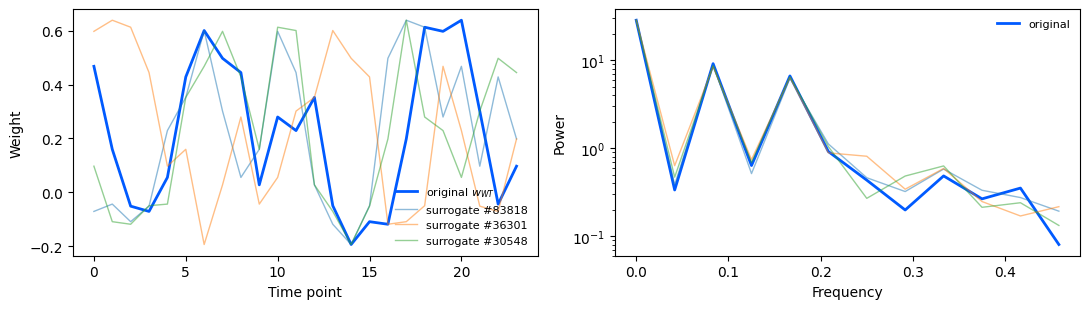

In [6]:
p_orig = np.square(np.abs(np.fft.fft(w)))
freq   = np.fft.fftfreq(n)
k      = np.argsort(freq)[n // 2:]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(w, color="#005aff", lw=2, label="original $w_{WT}$")
for i in np.random.randint(M, size=3):
    ax[0].plot(Ws[i] * w.std() + w.mean(), lw=1, alpha=0.5, label=f"surrogate #{i}")
ax[0].set_xlabel("Time point"); ax[0].set_ylabel("Weight")
ax[0].legend(fontsize=8, frameon=False)

ax[1].plot(freq[k], p_orig[k], color="#005aff", lw=2, label="original")
for i in np.random.randint(M, size=3):
    ps = np.square(np.abs(np.fft.fft(Ws[i] * w.std() + w.mean())))
    ax[1].plot(freq[k], ps[k], lw=1, alpha=0.5)
ax[1].set_yscale("log"); ax[1].set_xlabel("Frequency"); ax[1].set_ylabel("Power")
ax[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## 4. The test, vectorised

`run_test` takes a batch of standardised comparison signals `G` of shape `(b, n)` and returns

* `obs` — the observed correlations $r_{\mathrm{obs}}$, one per signal
* `thr` — the upper-$\alpha$ thresholds of the corresponding null distributions

A signal is called **positive** when `obs > thr`.

In [7]:
ALPHAS = [ALPHA_NOM, ALPHA_BONF]
QS     = [1 - a for a in ALPHAS]
LABELS = {ALPHA_NOM: "p = 0.05", ALPHA_BONF: f"p = 0.05/{N_GENES}"}

def run_test(G):
    '''G: (b, n) standardised signals -> observed r and per-alpha thresholds.'''
    obs  = G @ w_std / n                        # (b,)
    NULL = Ws @ G.T / n                         # (M, b)  null distributions
    thr  = np.quantile(NULL, QS, axis=0)        # (len(ALPHAS), b)
    return obs, thr

def make_signals(rho, b, rng):
    '''b synthetic comparison signals with population correlation rho to w_WT.'''
    eps = zscore(rng.standard_normal((b, n)))
    return zscore(rho * w_std + np.sqrt(max(0.0, 1 - rho**2)) * eps)

## 5. Calibration check — Type I error at $\rho = 0$

Before measuring power we verify the test is **correctly calibrated**: with no true correlation,
the false-positive rate must match the nominal level. If it were inflated, any power estimate
would be meaningless.

We also record the **critical correlation** $r_{\mathrm{crit}}$ — the observed $|r|$ a gene must
exceed to be called significant.

In [8]:
rng   = np.random.default_rng(7)
T_CAL = 5_000
CH    = 250

fp   = {a: 0 for a in ALPHAS}
crit = {a: [] for a in ALPHAS}

done = 0
while done < T_CAL:
    b = min(CH, T_CAL - done)
    G = zscore(rng.standard_normal((b, n)))          # rho = 0 : pure white noise
    obs, thr = run_test(G)
    for k, a in enumerate(ALPHAS):
        fp[a] += int((obs > thr[k]).sum())
        crit[a].extend(thr[k].tolist())
    done += b

print(f"=== Type I error (rho = 0, T = {T_CAL}) ===")
for a in ALPHAS:
    print(f"  {LABELS[a]:>12s} : empirical FPR = {fp[a]/T_CAL:.4f}   (target {a:.4f})")

print(f"\n=== Critical correlation r_crit ===")
for a in ALPHAS:
    q = crit[a]
    print(f"  {LABELS[a]:>12s} : median |r| = {np.median(q):.3f}   "
          f"IQR = [{np.quantile(q,.25):.3f}, {np.quantile(q,.75):.3f}]")

=== Type I error (rho = 0, T = 5000) ===
      p = 0.05 : empirical FPR = 0.0470   (target 0.0500)
   p = 0.05/21 : empirical FPR = 0.0018   (target 0.0024)

=== Critical correlation r_crit ===
      p = 0.05 : median |r| = 0.324   IQR = [0.276, 0.378]
   p = 0.05/21 : median |r| = 0.480   IQR = [0.424, 0.543]


## 6. Power sweep

For each $\rho$ on the grid we generate $T = 800$ synthetic comparison signals, run the test, and
record the fraction of positives.

In [9]:
rng   = np.random.default_rng(1)
power = {a: np.zeros(len(RHO_GRID)) for a in ALPHAS}

for j, rho in enumerate(RHO_GRID):
    hits = {a: 0 for a in ALPHAS}
    done = 0
    while done < T:
        b = min(CH, T - done)
        obs, thr = run_test(make_signals(rho, b, rng))
        for k, a in enumerate(ALPHAS):
            hits[a] += int((obs > thr[k]).sum())
        done += b
    for a in ALPHAS:
        power[a][j] = hits[a] / T

results = pd.DataFrame({
    "rho":                 RHO_GRID,
    "power_nominal_0.05":  power[ALPHA_NOM],
    "power_bonferroni_21": power[ALPHA_BONF],
})
results.to_csv(os.path.join(RESULT_DIR, "power_final_n24.csv"), index=False)
results.head()

,rho,power_nominal_0.05,power_bonferroni_21
0,0.00,0.03500,0.00125
1,0.02,0.05625,0.00250
2,0.04,0.07000,0.00250
3,0.06,0.08250,0.00125
4,0.08,0.10625,0.00250


### Minimum detectable correlation

$\rho_{80}$ is the true correlation at which the test reaches **80 % power** — the conventional
benchmark for an adequately powered study.

In [10]:
def rho_at_power(pw, target=0.8):
    '''Linear interpolation of the rho at which the power curve crosses `target`.'''
    for i in range(1, len(RHO_GRID)):
        if pw[i] >= target and pw[i-1] < target:
            x0, x1 = RHO_GRID[i-1], RHO_GRID[i]
            y0, y1 = pw[i-1], pw[i]
            return x0 + (target - y0) * (x1 - x0) / (y1 - y0)
    return np.nan

rho80 = {a: rho_at_power(power[a]) for a in ALPHAS}

print("=== rho at 80% power ===")
for a in ALPHAS:
    print(f"  {LABELS[a]:>12s} : rho_80 = {rho80[a]:.3f}")

print("\n=== Power at selected rho ===")
print(f"  {'rho':>5s} | {'p=0.05':>8s} | {'Bonferroni':>10s}")
for rt in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    j = int(np.argmin(np.abs(RHO_GRID - rt)))
    print(f"  {RHO_GRID[j]:5.2f} | {power[ALPHA_NOM][j]:8.2f} | {power[ALPHA_BONF][j]:10.2f}")

=== rho at 80% power ===
      p = 0.05 : rho_80 = 0.514
   p = 0.05/21 : rho_80 = 0.766

=== Power at selected rho ===
    rho |   p=0.05 | Bonferroni
   0.30 |     0.35 |       0.03
   0.40 |     0.53 |       0.06
   0.50 |     0.78 |       0.14
   0.60 |     0.94 |       0.27
   0.70 |     0.99 |       0.57
   0.80 |     1.00 |       0.91


## 7. Figure

**Panel A** — the power curve: true correlation strength (x) against positive rate (y), for the
uncorrected and Bonferroni-corrected thresholds. Shaded bands are Wilson 95 % confidence
intervals on the estimated proportion.

**Panel B** — the null distribution for a representative uncorrelated gene, with both
significance thresholds marked in correlation units.

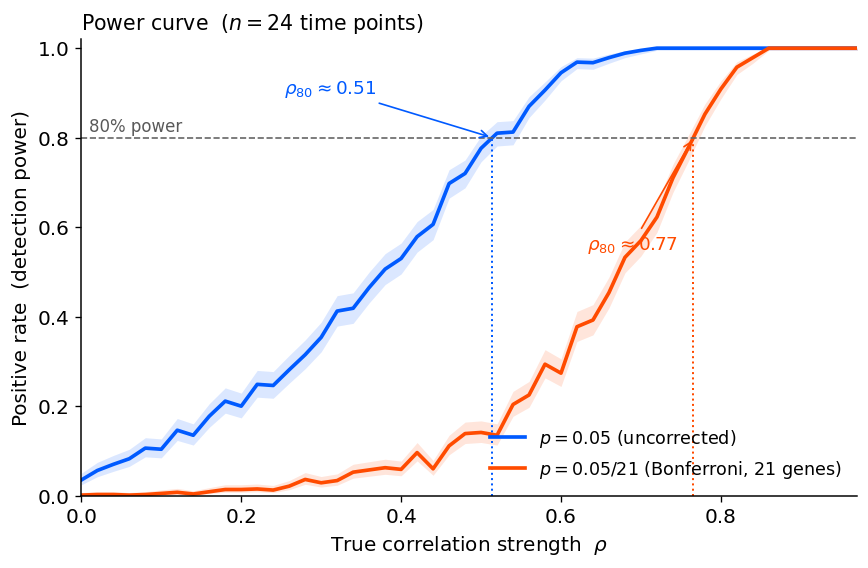

In [13]:
BLUE, VERM = "#005aff", "#ff4b00"          # colour-universal-design palette
plt.rcParams.update({
    "font.size": 12, "axes.linewidth": 0.9,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120,
})

def wilson(p, m, z=1.96):
    '''Wilson score interval for a binomial proportion.'''
    d = 1 + z**2 / m
    c = (p + z**2 / (2*m)) / d
    h = z * np.sqrt(p*(1-p)/m + z**2/(4*m**2)) / d
    return np.clip(c - h, 0, 1), np.clip(c + h, 0, 1)

fig, axA = plt.subplots(figsize=(7.4, 4.9))

for a, col, lab in [(ALPHA_NOM,  BLUE, r"$p=0.05$ (uncorrected)"),
                    (ALPHA_BONF, VERM, rf"$p=0.05/{N_GENES}$ (Bonferroni, {N_GENES} genes)")]:
    pw = power[a]
    lo, hi = np.array([wilson(p, T) for p in pw]).T
    axA.fill_between(RHO_GRID, lo, hi, color=col, alpha=0.14, lw=0)
    axA.plot(RHO_GRID, pw, "-", color=col, lw=2.2, label=lab)

axA.axhline(0.8, ls="--", color="0.4", lw=1)
axA.text(0.01, 0.815, "80% power", fontsize=10, color="0.35")
axA.plot([rho80[ALPHA_NOM]]*2,  [0, 0.8], ls=":", color=BLUE, lw=1.2)
axA.plot([rho80[ALPHA_BONF]]*2, [0, 0.8], ls=":", color=VERM, lw=1.2)
axA.annotate(rf"$\rho_{{80}}\approx{rho80[ALPHA_NOM]:.2f}$",
             xy=(rho80[ALPHA_NOM], 0.8), xytext=(rho80[ALPHA_NOM]-0.26, 0.90),
             fontsize=11, color=BLUE, arrowprops=dict(arrowstyle="->", color=BLUE, lw=1))
axA.annotate(rf"$\rho_{{80}}\approx{rho80[ALPHA_BONF]:.2f}$",
             xy=(rho80[ALPHA_BONF], 0.8), xytext=(rho80[ALPHA_BONF]-0.02, 0.55),
             fontsize=11, color=VERM, ha="right",
             arrowprops=dict(arrowstyle="->", color=VERM, lw=1))

axA.set_xlabel(r"True correlation strength  $\rho$")
axA.set_ylabel("Positive rate  (detection power)")
axA.set_xlim(0, 0.97); axA.set_ylim(0, 1.02)
axA.set_title(rf"Power curve  ($n={n}$ time points)", loc="left", fontsize=12.3)
axA.legend(loc="lower right", frameon=False, fontsize=10.5)

fig.tight_layout()
#fig.savefig(os.path.join(RESULT_DIR, "power_analysis_final.png"), dpi=200, bbox_inches="tight")
fig.savefig(os.path.join(RESULT_DIR, "power_analysis_final.pdf"), bbox_inches="tight")
plt.show()

In [21]:
pw[0]

0.00125

## 8. Summary

In [19]:
print(f"Sample size                     : n = {n} (48 points, even-numbered excluded)")
print(f"Surrogates                      : M = {M:,}")
print(f"Monte-Carlo trials per rho      : T = {T}")
print()
print(f"{'':16s} {'Type I':>8s} {'r_crit':>8s} {'rho_80':>8s}")
for a in ALPHAS:
    print(f"{LABELS[a]:16s} {fp[a]/T_CAL:8.4f} {np.median(crit[a]):8.3f} {rho80[a]:8.2f}")

Sample size                     : n = 24 (48 points, even-numbered excluded)
Surrogates                      : M = 100,000
Monte-Carlo trials per rho      : T = 800

                   Type I   r_crit   rho_80
p = 0.05           0.0470    0.324     0.51
p = 0.05/21        0.0018    0.480     0.77


---

## Interpretation — response to comment #2-6

**The test is correctly calibrated.** At $\rho = 0$ the empirical false-positive rate matches the
nominal level at both thresholds. The surrogate test is therefore valid and, if anything,
conservative — it does not manufacture significance.

**Under Bonferroni correction the test only detects strong associations.** With $n = 24$ time
points and correction for 21 genes, a gene must reach $|r| \gtrsim 0.48$ to be called significant,
and 80 % power is attained only for $\rho \gtrsim 0.77$. Moderate true associations
($\rho = 0.3\text{–}0.5$) are detected only a small fraction of the time.

**Therefore the 4 significant genes are a conservative lower bound.** The small number reflects
the statistical power available at this sample size combined with multiple-testing correction —
not an absence of biological signal. Conversely, precisely *because* the test is conservative and
well-calibrated, the genes that do pass correspond to strong, robust associations, which supports
the reliability of their biological interpretation.

**Limitation of this analysis.** The synthetic comparison signals use white noise. Real
gene-expression profiles are autocorrelated, which raises the critical correlation further and
lowers power. The power reported here is therefore an **optimistic upper bound**.

---

### Reference

Venema, V., Ament, F. & Simmer, C. (2006). A stochastic iterative amplitude adjusted Fourier
Transform algorithm with improved accuracy. *Nonlinear Processes in Geophysics*, **13**, 321–328.
[doi:10.5194/npg-13-321-2006](https://doi.org/10.5194/npg-13-321-2006) —
implementation: <https://github.com/mlcs/iaaft>